# Conv Layer

## Mini-Graufstufenbild erzeugen

In [1]:
import torch

x = torch.tensor([[
    [1,2,3,0,0],
    [4,5,6,0,0],
    [7,8,9,0,0],
    [0,0,0,0,0],
    [0,0,0,0,0]
    ]], dtype=torch.float32)

In [2]:
type(x)

torch.Tensor

In [3]:
x.shape

torch.Size([1, 5, 5])

## Eine Conv-Layer mit zwei Filtern erzeugen

In [4]:
import torch.nn as nn
conv = nn.Conv2d(in_channels=1, out_channels=2, kernel_size=3, bias=False)

In [5]:
type(conv)

torch.nn.modules.conv.Conv2d

## Mal die Gewichte der Filterkernel sehen

In [6]:
conv.weight

Parameter containing:
tensor([[[[ 0.2946,  0.0902, -0.0052],
          [ 0.1582,  0.0817, -0.0723],
          [-0.1683,  0.2414, -0.2466]]],


        [[[ 0.2573,  0.2184,  0.1540],
          [ 0.2301, -0.0607,  0.2447],
          [ 0.0311, -0.0234,  0.1893]]]], requires_grad=True)

In [7]:
conv.weight.shape

torch.Size([2, 1, 3, 3])

## Jetzt das Bild x mit der Conv-Layer filtern

In [8]:
y = conv(x)

In [9]:
type(y)

torch.Tensor

In [10]:
y.shape

torch.Size([2, 3, 3])

In [11]:
y

tensor([[[-0.3997,  2.9673,  0.3182],
         [ 2.7084,  4.0153,  3.1912],
         [ 2.7369,  3.1689,  2.6513]],

        [[ 4.9750,  1.9940,  2.4321],
         [ 6.3719,  3.8912,  3.6145],
         [ 4.9340,  4.0240,  2.3157]]], grad_fn=<SqueezeBackward1>)

## Filterkernelmatrizen per Hand setzen

In [12]:
with torch.no_grad():
    conv.weight[0] = torch.tensor( [[
        [
        [-1,-1,-1],
        [0,0,0],
        [1,1,1]
        ]
    ]])

    conv.weight[1] = torch.tensor( [[
        [
        [-1,0,1],
        [-1,0,1],
        [-1,0,1]
        ]
    ]])    

y = conv(x)

In [16]:
conv.weight

Parameter containing:
tensor([[[[-1., -1., -1.],
          [ 0.,  0.,  0.],
          [ 1.,  1.,  1.]]],


        [[[-1.,  0.,  1.],
          [-1.,  0.,  1.],
          [-1.,  0.,  1.]]]], requires_grad=True)

## Die Filterantwort verstehen

In [13]:
y.shape

torch.Size([2, 3, 3])

In [14]:
y

tensor([[[ 18.,  12.,   6.],
         [-15., -11.,  -6.],
         [-24., -17.,  -9.]],

        [[  6., -15., -18.],
         [  4., -13., -15.],
         [  2.,  -8.,  -9.]]], grad_fn=<SqueezeBackward1>)

In [17]:
x

tensor([[[1., 2., 3., 0., 0.],
         [4., 5., 6., 0., 0.],
         [7., 8., 9., 0., 0.],
         [0., 0., 0., 0., 0.],
         [0., 0., 0., 0., 0.]]])

In [18]:
x[0,0:3,0:3].flatten()

tensor([1., 2., 3., 4., 5., 6., 7., 8., 9.])

In [19]:
conv.weight[0].flatten()

tensor([-1., -1., -1.,  0.,  0.,  0.,  1.,  1.,  1.], grad_fn=<ViewBackward0>)

In [21]:
-1*(1+2+3) + 1*(7+8+9)

18

In [22]:
torch.dot(x[0,0:3,0:3].flatten(), conv.weight[0].flatten())

tensor(18., grad_fn=<DotBackward0>)

In [26]:
# Stride
s = 1

torch.dot(x[0,0:3,0+s:3+s].flatten(), conv.weight[0].flatten())

tensor(12., grad_fn=<DotBackward0>)

In [27]:
y

tensor([[[ 18.,  12.,   6.],
         [-15., -11.,  -6.],
         [-24., -17.,  -9.]],

        [[  6., -15., -18.],
         [  4., -13., -15.],
         [  2.,  -8.,  -9.]]], grad_fn=<SqueezeBackward1>)

## Mal ein ganzes Bild filtern

In [36]:
# Bild laden (Graustufen)
import cv2
fname = "/home/juebrauer/link_to_vcd/08_datasets/66_test_bilder_dl4cv_ws26/campus_hochschule_kempten.png"
img = cv2.imread(fname)
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

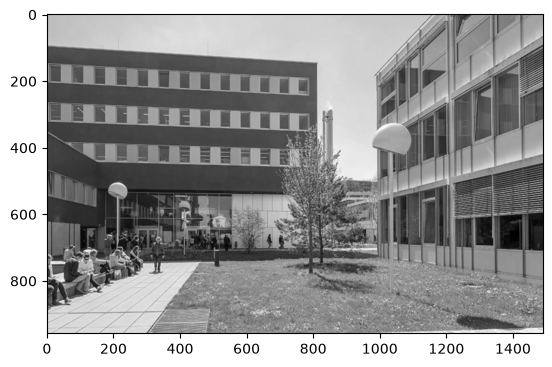

In [37]:
# Bild anzeigen
import matplotlib.pyplot as plt
plt.imshow(img, cmap="gray")
plt.show()

In [38]:
# Bild als Tensor vorbereiten
import torchvision.transforms as transforms

transform = transforms.Compose([
    #transforms.Resize((128, 128)),
    transforms.ToTensor()
])
x = transform(img).unsqueeze(0)  # (1, 1, H, W)
x.shape

torch.Size([1, 1, 958, 1490])

In [54]:
# Filterschicht erzeugen
conv = nn.Conv2d(1, 2, kernel_size=3, padding=1, bias=False)

# Filter per Hand setzen
sobel = torch.tensor([[
    [[-1, -1, -1],
     [ 0,  0,  0],
     [ 1,  1,  1]]
]])

blur = torch.tensor([[
    [[1, 1, 1],
     [1, 1, 1],
     [1, 1, 1]]
]]) / 9.0

with torch.no_grad():
    conv.weight[0] = blur
    conv.weight[1] = sobel

    # Bild filtern
    y = conv(x)

In [55]:
x.shape

torch.Size([1, 1, 958, 1490])

In [56]:
y.shape

torch.Size([1, 2, 958, 1490])

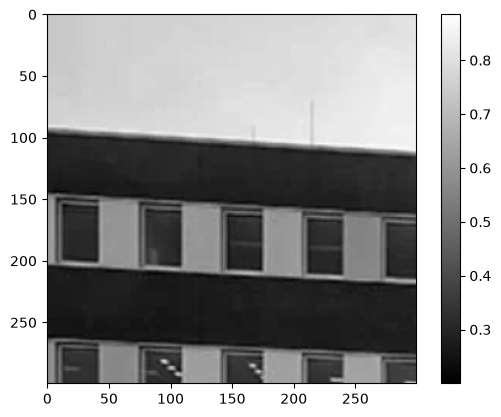

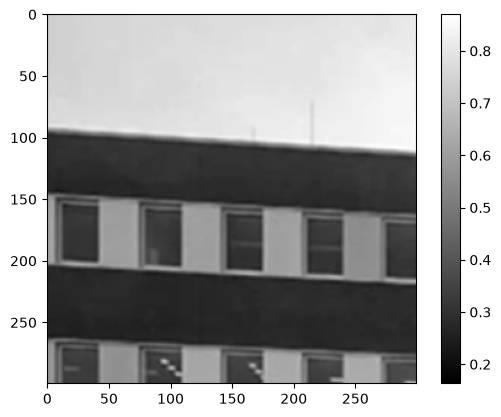

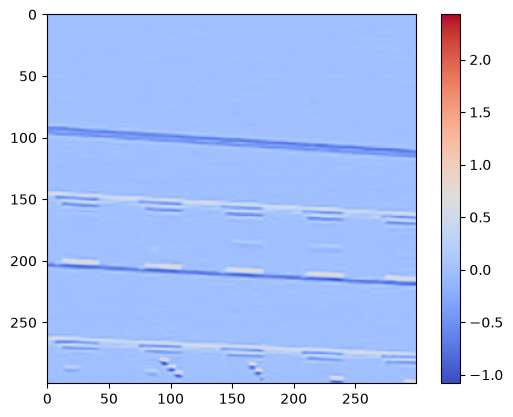

In [73]:
# Anzeigen
N = 300
plt.imshow(x[0,0,:N,:N].numpy(), cmap="gray")
plt.colorbar()
plt.show()

plt.imshow(y[0,0,:N,:N].detach().numpy(), cmap="gray")
plt.colorbar()
plt.show()

plt.imshow(y[0,1,:N,:N].detach().numpy(), cmap="coolwarm")
plt.colorbar()
plt.show()


In [74]:
y[0,1,:N,:N].min()

tensor(-1.0824)

In [75]:
y[0,1,:N,:N].max()

tensor(2.4353)

# Pool Layer


## Nochmal ein Testbild

In [76]:
x = torch.tensor([[
    [1,2,3,0,0],
    [4,5,6,0,0],
    [7,8,9,0,0],
    [0,0,0,0,0],
    [0,0,0,0,0]
    ]], dtype=torch.float32)


## Jetzt eine neue Schicht

In [77]:
pool = nn.MaxPool2d(kernel_size=2, stride=None)
y = pool(x)

In [78]:
y

tensor([[[5., 6.],
         [8., 9.]]])

In [79]:
y.shape

torch.Size([1, 2, 2])

In [82]:
# geht nicht, denn es gibt keine Gewichte:
# pool.weight

In [83]:
pool = nn.MaxPool2d(kernel_size=2, stride=1)
y = pool(x)

In [84]:
y

tensor([[[5., 6., 6., 0.],
         [8., 9., 9., 0.],
         [8., 9., 9., 0.],
         [0., 0., 0., 0.]]])

In [85]:
x

tensor([[[1., 2., 3., 0., 0.],
         [4., 5., 6., 0., 0.],
         [7., 8., 9., 0., 0.],
         [0., 0., 0., 0., 0.],
         [0., 0., 0., 0., 0.]]])